In [12]:
import pandas as pd

df = pd.read_csv('spam_emails_en.csv')
print("Өгөгдлийн хэмжээ (мөр, багана):", df.shape)
print("\nАнгиудын тархалт:\n", df['label'].value_counts())

df['n_words'] = df['text'].str.split().str.len()
print("\nДундаж үгийн тоо:\n", df.groupby('label')['n_words'].mean())

longest_idx = df['n_words'].idxmax()
print(f"\nХамгийн урт имэйл ({df.loc[longest_idx, 'n_words']} үгтэй, label={df.loc[longest_idx, 'label']}):")
print(df.loc[longest_idx, 'text'][:300], "...")

print("\n---Random 10 email ---")
for idx, row in df.sample(10, random_state=0).iterrows():
    print(f"[{row['label']}] {row['text']}")

Өгөгдлийн хэмжээ (мөр, багана): (506, 2)

Ангиудын тархалт:
 label
ham     341
spam    165
Name: count, dtype: int64

Дундаж үгийн тоо:
 label
ham     24.020528
spam    19.424242
Name: n_words, dtype: float64

Хамгийн урт имэйл (40 үгтэй, label=spam):
Team schedule for Monday - Here is the plan for Monday: standup at 2:00 pm, code review after lunch, and a short demo at the end of the day. Let me know No need to worry about the account issue. ...

---Random 10 email ---
[ham] Library book due - Your book on calculus is due on Tuesday. Please return or renew it at the front desk. About the account question, we can talk later.
[spam] Get a loan today - Bad credit? No problem! Instant cash loan up to $6,000 approved in minutes. Apply now http://promo-deals.xyz/c
[ham] Dinner tonight - Mom said dinner is at 8:30 tonight. Can you pick up some bread on your way home? Cheers The password thing is sorted now.
[spam] Double your bitcoin - Invest $500 today and get guaranteed returns. Act now, l

In [13]:
from collections import Counter

mini_data = [
    ('spam', 'free money now'),
    ('spam', 'win free prize now'),
    ('spam', 'free gift'),
    ('ham', 'meeting at noon'),
    ('ham', 'project meeting now'),
    ('ham', 'lunch at noon')
]

alpha = 1.0
vocab = set(w for _, txt in mini_data for w in txt.split())
V = len(vocab)

counts = {'spam': Counter(), 'ham': Counter()}
totals = {'spam': 0, 'ham': 0}
doc_counts = Counter(lbl for lbl, _ in mini_data)

for lbl, txt in mini_data:
    words = txt.split()
    counts[lbl].update(words)
    totals[lbl] += len(words)

priors = {c: doc_counts[c] / len(mini_data) for c in ['spam', 'ham']}
print(f"V = {V}, vocab = {sorted(vocab)}")
print(f"Нийт token: spam={totals['spam']}, ham={totals['ham']}")
print(f"Prior: {priors}")

def p_word(w, c, a=1.0):
    return (counts[c][w] + a) / (totals[c] + a * V)

for w in ['free', 'now', 'meeting']:
    print(f"P({w}|spam) = {p_word(w, 'spam'):.4f}, P({w}|ham) = {p_word(w, 'ham'):.4f}")

def predict_mini(text, a=1.0):
    words = text.split()
    scores = {}
    for c in ['spam', 'ham']:
        s = priors[c]
        for w in words:
            s *= p_word(w, c, a)
        scores[c] = s
    norm = scores['spam'] + scores['ham']
    p_spam = scores['spam'] / norm if norm > 0 else 0
    return scores, p_spam

for q in ['free now', 'meeting now', 'free meeting']:
    sc_1, p_1 = predict_mini(q, a=1.0)
    sc_0, p_0 = predict_mini(q, a=0.0)
    print(f"\nИмэйл: '{q}'")
    print(f"  Smoothing (a=1): scores={sc_1}, P(spam|имэйл)={p_1:.4f}")
    print(f"  Smoothing-гүй (a=0): scores={sc_0}")

V = 11, vocab = ['at', 'free', 'gift', 'lunch', 'meeting', 'money', 'noon', 'now', 'prize', 'project', 'win']
Нийт token: spam=9, ham=9
Prior: {'spam': 0.5, 'ham': 0.5}
P(free|spam) = 0.2000, P(free|ham) = 0.0500
P(now|spam) = 0.1500, P(now|ham) = 0.1000
P(meeting|spam) = 0.0500, P(meeting|ham) = 0.1500

Имэйл: 'free now'
  Smoothing (a=1): scores={'spam': 0.015, 'ham': 0.0025000000000000005}, P(spam|имэйл)=0.8571
  Smoothing-гүй (a=0): scores={'spam': 0.037037037037037035, 'ham': 0.0}

Имэйл: 'meeting now'
  Smoothing (a=1): scores={'spam': 0.00375, 'ham': 0.0075}, P(spam|имэйл)=0.3333
  Smoothing-гүй (a=0): scores={'spam': 0.0, 'ham': 0.012345679012345678}

Имэйл: 'free meeting'
  Smoothing (a=1): scores={'spam': 0.005000000000000001, 'ham': 0.00375}, P(spam|имэйл)=0.5714
  Smoothing-гүй (a=0): scores={'spam': 0.0, 'ham': 0.0}


In [14]:
import re
from sklearn.model_selection import train_test_split

def tokenize(s):
    return re.findall(r"[a-z0-9$%']+", s.lower())

train, test = train_test_split(df, test_size=0.2, random_state=42, stratify=df['label'])
print("Train/Test хэмжээ:", len(train), len(test), test['label'].value_counts().to_dict())

train_vocab = set(w for txt in train['text'] for w in tokenize(txt))
print("Train үгсийн сангийн хэмжээ (V):", len(train_vocab))

print("Жишээ tokenize:", tokenize('YOU WON $1,000,000!!! Click NOW'))

Train/Test хэмжээ: 404 102 {'ham': 69, 'spam': 33}
Train үгсийн сангийн хэмжээ (V): 364
Жишээ tokenize: ['you', 'won', '$1', '000', '000', 'click', 'now']


In [15]:
from collections import Counter
import math

class NaiveBayes:
    def __init__(self, alpha=1.0):
        self.alpha = alpha
        self.classes = []
        self.priors = {}
        self.word_counts = {}
        self.total_tokens = {}
        self.vocab = set()

    def fit(self, texts, labels):
        label_counts = Counter(labels)
        n_docs = len(labels)
        self.classes = list(label_counts.keys())
        self.priors = {c: label_counts[c] / n_docs for c in self.classes}
        self.word_counts = {c: Counter() for c in self.classes}
        self.total_tokens = {c: 0 for c in self.classes}
        self.vocab = set()

        for text, c in zip(texts, labels):
            tokens = tokenize(text)
            self.word_counts[c].update(tokens)
            self.total_tokens[c] += len(tokens)
            self.vocab.update(tokens)
        return self

    def log_score(self, text, c):
        score = math.log(self.priors[c])
        V = len(self.vocab)
        denom = self.total_tokens[c] + self.alpha * V
        for w in tokenize(text):
            if w in self.vocab:
                prob = (self.word_counts[c][w] + self.alpha) / denom
                score += math.log(prob)
        return score

    def predict(self, text):
        return max(self.classes, key=lambda c: self.log_score(text, c))

nb_scratch = NaiveBayes(alpha=1.0).fit(train['text'], train['label'])
scratch_preds = [nb_scratch.predict(t) for t in test['text']]
scratch_acc = sum(p == y for p, y in zip(scratch_preds, test['label'])) / len(test)
print(f"Тэгээс бичсэн NaiveBayes Accuracy: {scratch_acc:.4f}")

sample_emails = [
    "Congratulations winner, click the link to claim your free prize",
    "What time does the database class start tomorrow",
    "There is a discount book sale on campus, want to go together"
]
print("\n--- 3 жишээ имэйлийн таамаглал ---")
for e in sample_emails:
    print(f"Таамаглал: {nb_scratch.predict(e):<5} | Имэйл: {e}")

print("\n0.001 ** 200 =", 0.001 ** 200, "(хэт бага тоо тул 0.0 болж underflow болдог)")

Тэгээс бичсэн NaiveBayes Accuracy: 0.9608

--- 3 жишээ имэйлийн таамаглал ---
Таамаглал: spam  | Имэйл: Congratulations winner, click the link to claim your free prize
Таамаглал: ham   | Имэйл: What time does the database class start tomorrow
Таамаглал: ham   | Имэйл: There is a discount book sale on campus, want to go together

0.001 ** 200 = 0.0 (хэт бага тоо тул 0.0 болж underflow болдог)


In [16]:
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB

cv = CountVectorizer(token_pattern=r"[a-z0-9$%']+")
Xtr = cv.fit_transform(train['text'])
Xte = cv.transform(test['text'])

clf = MultinomialNB(alpha=1.0).fit(Xtr, train['label'])
pred = clf.predict(Xte)

print(f"sklearn MultinomialNB Accuracy: {(pred == test['label']).mean():.4f}")
print("Xtr матрицын хэмжээ:", Xtr.shape)

agreement = sum(p1 == p2 for p1, p2 in zip(scratch_preds, pred)) / len(pred)
print(f"Scratch болон sklearn таамаглалын тохиролт: {agreement * 100:.2f}%")

sklearn MultinomialNB Accuracy: 0.9608
Xtr матрицын хэмжээ: (404, 364)
Scratch болон sklearn таамаглалын тохиролт: 100.00%


In [17]:
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score

cm = confusion_matrix(test['label'], pred, labels=['ham', 'spam'])
print("Confusion Matrix (мөр=бодит [ham, spam], багана=таамаглал [ham, spam]):\n", cm)

tn, fp, fn, tp = cm.ravel()
man_acc = (tp + tn) / (tp + tn + fp + fn)
man_prec = tp / (tp + fp)
man_rec = tp / (tp + fn)
man_f1 = 2 * man_prec * man_rec / (man_prec + man_rec)

print(f"\nГараар бодсон  -> Acc: {man_acc:.4f}, Prec: {man_prec:.4f}, Rec: {man_rec:.4f}, F1: {man_f1:.4f}")
print(f"sklearn.metrics-> Acc: {accuracy_score(test['label'], pred):.4f}, "
      f"Prec: {precision_score(test['label'], pred, pos_label='spam'):.4f}, "
      f"Rec: {recall_score(test['label'], pred, pos_label='spam'):.4f}, "
      f"F1: {f1_score(test['label'], pred, pos_label='spam'):.4f}")

rows = []
for a in [0.01, 1.0, 5.0]:
    m = MultinomialNB(alpha=a).fit(Xtr, train['label'])
    p = m.predict(Xte)
    rows.append({
        'alpha': a,
        'Accuracy': round(accuracy_score(test['label'], p), 4),
        'Precision': round(precision_score(test['label'], p, pos_label='spam'), 4),
        'Recall': round(recall_score(test['label'], p, pos_label='spam'), 4),
        'F1': round(f1_score(test['label'], p, pos_label='spam'), 4),
    })

print("\n--- Alpha өөрчлөлтийн хүснэгт ---")
display(pd.DataFrame(rows))

Confusion Matrix (мөр=бодит [ham, spam], багана=таамаглал [ham, spam]):
 [[68  1]
 [ 3 30]]

Гараар бодсон  -> Acc: 0.9608, Prec: 0.9677, Rec: 0.9091, F1: 0.9375
sklearn.metrics-> Acc: 0.9608, Prec: 0.9677, Rec: 0.9091, F1: 0.9375

--- Alpha өөрчлөлтийн хүснэгт ---


,alpha,Accuracy,Precision,Recall,F1
0,0.01,0.9608,0.9677,0.9091,0.9375
1,1.00,0.9608,0.9677,0.9091,0.9375
2,5.00,0.9608,0.9677,0.9091,0.9375


In [18]:
errors = test[pred != test['label']].copy()
errors['predicted'] = pred[pred != test['label']]

print(f"Нийт буруу таамаглал: {len(errors)}\n")
for idx, row in errors.iterrows():
    print(f"ID={idx} | Бодит: {row['label']:<4} | Модель: {row['predicted']:<4}")
    print(f"Текст: {row['text']}")
    print("-" * 70)

Нийт буруу таамаглал: 4

ID=147 | Бодит: spam | Модель: ham 
Текст: Assignment 8 feedback - Hi, I have marked your data mining assignment. Please see me after class on Tuesday if you have questions. No need to worry about the discount issue.
----------------------------------------------------------------------
ID=184 | Бодит: spam | Модель: ham 
Текст: Group presentation - Our web design presentation is on Friday. Let us meet at 8:30 to practice once more. Thanks
----------------------------------------------------------------------
ID=168 | Бодит: spam | Модель: ham 
Текст: Assignment 5 feedback - Hi, I have marked your database assignment. Please see me after class on Friday if you have questions.
----------------------------------------------------------------------
ID=406 | Бодит: ham  | Модель: spam
Текст: HAVE WON $4,000,000!!! - winner! Click the link now to claim your prize before it http://win-prize.biz/x Hurry, this offer ends today See attached
-----------------------------

0.99-ээс их итгэлтэй таамаглалын хувь: 100.00%

Буруу таамаглалуудын магадлалын итгэл:
ID=147 | Бодит=spam, Таамаглал=ham | P(ham)=1.000000, P(spam)=0.000000
ID=184 | Бодит=spam, Таамаглал=ham | P(ham)=1.000000, P(spam)=0.000000
ID=168 | Бодит=spam, Таамаглал=ham | P(ham)=1.000000, P(spam)=0.000000
ID=406 | Бодит=ham, Таамаглал=spam | P(ham)=0.000000, P(spam)=1.000000

Спамыг хамгийн их заадаг 8 үг: ['get' 'a1b2' 'ly' 'bit' 'win' 'loan' '000' 'one']
Энгийнийг хамгийн их заадаг 8 үг: ['assignment' 'late' 'draft' 'statistics' 'book' 'class' 'marked' 'due']

Босго 0.5 үеийн Accuracy : 0.9608
Босго 0.99 үеийн Accuracy: 0.9608


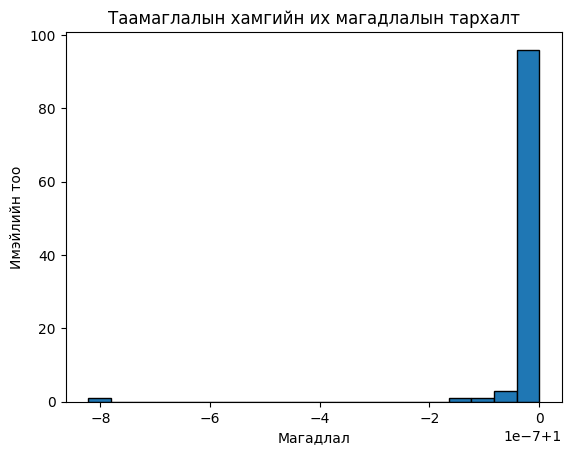

In [19]:
import numpy as np
import matplotlib.pyplot as plt

probs = clf.predict_proba(Xte)
max_probs = probs.max(axis=1)

print(f"0.99-ээс их итгэлтэй таамаглалын хувь: {(max_probs > 0.99).mean() * 100:.2f}%")

si = list(clf.classes_).index('spam')
hi = 1 - si

print("\nБуруу таамаглалуудын магадлалын итгэл:")
err_probs = probs[pred != test['label']]
for (idx, row), pr in zip(errors.iterrows(), err_probs):
    print(f"ID={idx} | Бодит={row['label']}, Таамаглал={row['predicted']} | P(ham)={pr[hi]:.6f}, P(spam)={pr[si]:.6f}")

ratio = clf.feature_log_prob_[si] - clf.feature_log_prob_[hi]
vocab_arr = np.array(cv.get_feature_names_out())
print("\nСпамыг хамгийн их заадаг 8 үг:", vocab_arr[np.argsort(-ratio)[:8]])
print("Энгийнийг хамгийн их заадаг 8 үг:", vocab_arr[np.argsort(ratio)[:8]])

pred_99 = np.where(probs[:, si] >= 0.99, 'spam', 'ham')
print(f"\nБосго 0.5 үеийн Accuracy : {(pred == test['label']).mean():.4f}")
print(f"Босго 0.99 үеийн Accuracy: {(pred_99 == test['label']).mean():.4f}")

plt.hist(max_probs, bins=20, edgecolor='black')
plt.title("Таамаглалын хамгийн их магадлалын тархалт")
plt.xlabel("Магадлал")
plt.ylabel("Имэйлийн тоо")
plt.show()

In [20]:
from sklearn.naive_bayes import BernoulliNB
from sklearn.feature_extraction.text import TfidfVectorizer

custom_emails = [
    ("ham", "Hey, are you free after the lecture to discuss our group project?"),
    ("ham", "I need to transfer the prize money for our hackathon team dinner tonight."),
    ("ham", "Please review the attached database lab report before Friday noon."),
    ("ham", "Mom asked if we are having lunch together this weekend."),
    ("ham", "The professor postponed tomorrow's morning class to 2 PM."),
    # 5 спам (spam) - сүүлийн хоёр нь шууд спам үг багатай хэцүү тохиолдол
    ("spam", "CONGRATULATIONS! You won $5000 cash! Click here to claim your free prize now!"),
    ("spam", "URGENT: Your bank account is suspended. Verify your password immediately via this link."),
    ("spam", "Limited time offer! 90% discount on luxury watches, buy now!"),
    ("spam", "Hi, I saw your profile and have an easy remote opportunity paying daily, reply yes."),
    ("spam", "Confirm your shipping fee of $1.99 today so our courier can release your package.")
]

custom_texts = [t for _, t in custom_emails]
custom_true = [l for l, _ in custom_emails]
X_custom = cv.transform(custom_texts)
c_preds = clf.predict(X_custom)
c_probs = clf.predict_proba(X_custom)[:, si]

res_df = pd.DataFrame({
    'Бодит': custom_true,
    'Таамаглал': c_preds,
    'P(spam)': np.round(c_probs, 4),
    'Зөв эсэх': [t == p for t, p in zip(custom_true, c_preds)],
    'Имэйл': [txt[:55] + '...' for txt in custom_texts]
})
display(res_df)

extra_tests = [
    "Quantum computer",
    "Танд 1,000,000 төгрөгийн сугалаа таарлаа, яг одоо линк дээр дарна уу!",
    "Вы выиграли миллион рублей, нажмите на ссылку прямо сейчас!"
]
for txt in extra_tests:
    p = clf.predict_proba(cv.transform([txt]))[0]
    print(f"'{txt}' -> {clf.predict(cv.transform([txt]))[0]} (P(ham)={p[hi]:.4f}, P(spam)={p[si]:.4f})")

bnb = BernoulliNB(alpha=1.0).fit(Xtr, train['label'])
bnb_pred = bnb.predict(Xte)

tfidf = TfidfVectorizer(token_pattern=r"[a-z0-9$%']+")
Xtr_tf = tfidf.fit_transform(train['text'])
Xte_tf = tfidf.transform(test['text'])
mnb_tf = MultinomialNB(alpha=1.0).fit(Xtr_tf, train['label'])
tf_pred = mnb_tf.predict(Xte_tf)

comp_df = pd.DataFrame([
    {'Загвар': 'Count + MultinomialNB', 'Accuracy': accuracy_score(test['label'], pred),
     'Precision': precision_score(test['label'], pred, pos_label='spam'),
     'Recall': recall_score(test['label'], pred, pos_label='spam'),
     'F1': f1_score(test['label'], pred, pos_label='spam')},
    {'Загвар': 'Count + BernoulliNB', 'Accuracy': accuracy_score(test['label'], bnb_pred),
     'Precision': precision_score(test['label'], bnb_pred, pos_label='spam'),
     'Recall': recall_score(test['label'], bnb_pred, pos_label='spam'),
     'F1': f1_score(test['label'], bnb_pred, pos_label='spam')},
    {'Загвар': 'TF-IDF + MultinomialNB', 'Accuracy': accuracy_score(test['label'], tf_pred),
     'Precision': precision_score(test['label'], tf_pred, pos_label='spam'),
     'Recall': recall_score(test['label'], tf_pred, pos_label='spam'),
     'F1': f1_score(test['label'], tf_pred, pos_label='spam')}
])
print("\n--- Загваруудын харьцуулалт ---")
display(comp_df.round(4))

,Бодит,Таамаглал,P(spam),Зөв эсэх,Имэйл
0,ham,ham,0.0010,True,"Hey, are you free after the lecture to discuss..."
1,ham,ham,0.0060,True,I need to transfer the prize money for our hac...
2,ham,ham,0.0000,True,Please review the attached database lab report...
3,ham,ham,0.0091,True,Mom asked if we are having lunch together this...
4,ham,ham,0.0009,True,The professor postponed tomorrow's morning cla...
5,spam,spam,1.0000,True,CONGRATULATIONS! You won $5000 cash! Click her...
6,spam,spam,1.0000,True,URGENT: Your bank account is suspended. Verify...
7,spam,spam,1.0000,True,Limited time offer! 90% discount on luxury wat...
8,spam,spam,0.7437,True,"Hi, I saw your profile and have an easy remote..."
9,spam,spam,0.9976,True,Confirm your shipping fee of $1.99 today so ou...


'Quantum computer' -> ham (P(ham)=0.6733, P(spam)=0.3267)
'Танд 1,000,000 төгрөгийн сугалаа таарлаа, яг одоо линк дээр дарна уу!' -> spam (P(ham)=0.0023, P(spam)=0.9977)
'Вы выиграли миллион рублей, нажмите на ссылку прямо сейчас!' -> ham (P(ham)=0.6733, P(spam)=0.3267)

--- Загваруудын харьцуулалт ---


,Загвар,Accuracy,Precision,Recall,F1
0,Count + MultinomialNB,0.9608,0.9677,0.9091,0.9375
1,Count + BernoulliNB,0.9608,0.9677,0.9091,0.9375
2,TF-IDF + MultinomialNB,0.9608,0.9677,0.9091,0.9375
